## CMPSC 105 Lab 07: Interpreting Hypothesis Tests

Your name(s): Artemii Otbliesk, Andrei Conwell


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# 1. DATA GENERATION (Run this cell to load your "lab_data")

# Generate doomscolling data
n_users = 1000

user_baselines = np.random.gamma(shape=3.0, scale=40.0, size=n_users)
standard_time = user_baselines + np.random.normal(loc=0, scale=10, size=n_users)
new_time = user_baselines + np.random.normal(loc=1.5, scale=10, size=n_users)
df_doomscrolling = pd.DataFrame({
    'user_id': np.arange(n_users),
    'standard_time': standard_time,
    'new_time': new_time
})
df_doomscrolling['difference'] = df_doomscrolling['new_time'] - df_doomscrolling['standard_time']
df_doomscrolling = df_doomscrolling.sample(frac=1, ignore_index=True)
    

# Generate e-commerce A/B test Data
blue_spending = np.random.normal(loc=42.50, scale=25.0, size=2000)
green_spending = np.random.normal(loc=43.10, scale=25.0, size=2000)
blue_spending = np.clip(blue_spending, a_min=0, a_max=None)
green_spending = np.clip(green_spending, a_min=0, a_max=None)

df_ecommerce = pd.DataFrame({
    'button_color': ['Blue'] * 2000 + ['Green'] * 2000,
    'spending': np.concatenate([blue_spending, green_spending])
})
df_ecommerce = df_ecommerce.sample(frac=1, ignore_index=True)

print("Datasets generated successfully!")


Datasets generated successfully!


### Scenario 1: The E-Commerce A/B Test

An e-commerce company is conducting an **A/B test** to determine the effect of button color on user spending for their shopping app. An A/B test is a controlled experiment where two or more variants of a single variable are compared to determine which performs better. In this case, the variable is the button color, and the outcome is user spending. 

Users are randomly assigned to see either a blue or green button, and their spending is recorded. The goal is to assess whether the button color influences the amount users spend.

In [4]:
df_ecommerce.head()

,button_color,spending
0,Green,18.070728
1,Green,43.302381
2,Blue,41.015935
3,Green,48.664621
4,Green,49.182121


In [5]:
# Calculate the observed difference in means
ecomm_means = df_ecommerce.groupby('button_color')['spending'].mean()
obs_diff_ecomm = ecomm_means['Green'] - ecomm_means['Blue']

print(f"Blue Button Mean: ${ecomm_means['Blue']:.2f}")
print(f"Green Button Mean: ${ecomm_means['Green']:.2f}")
print(f"Observed Difference: ${obs_diff_ecomm:.2f}")


Blue Button Mean: $42.69
Green Button Mean: $43.19
Observed Difference: $0.51


We can test whether the differenece between the green and blue button spending is statistically significant using a permutation test, where we repeatedly shuffle the button color labels and calculate the difference in mean spending between the green and blue buttons. This generates a null distribution of differences, which we can then compare to the observed difference to compute a p-value.

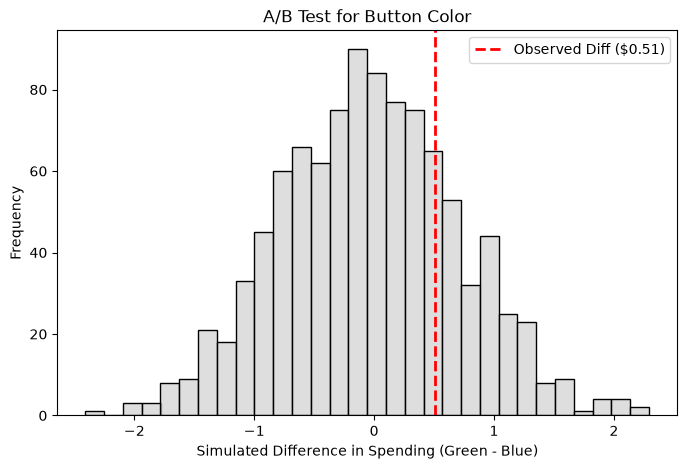

P-value for A/B Test (Button Color): 0.7770


In [6]:
# Permutation test
n_iter = 1000
simulated_diffs_ecomm = np.zeros(n_iter)

spending_vals = df_ecommerce['spending'].values
color_labels = df_ecommerce['button_color'].values

for i in range(n_iter):
    # Shuffle the labels
    shuffled = np.random.permutation(color_labels)
    
    # Calculate simulated means
    green_mean = spending_vals[shuffled == 'Green'].mean()
    blue_mean = spending_vals[shuffled == 'Blue'].mean()
    
    # Store the difference
    simulated_diffs_ecomm[i] = green_mean - blue_mean

plt.figure(figsize=(8, 5))
sns.histplot(simulated_diffs_ecomm, bins=30, color='lightgray', edgecolor='black')
plt.axvline(obs_diff_ecomm, color='red', linestyle='dashed', linewidth=2, label=f'Observed Diff (${obs_diff_ecomm:.2f})')
plt.title('A/B Test for Button Color')
plt.xlabel('Simulated Difference in Spending (Green - Blue)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

p_value_ecomm = (simulated_diffs_ecomm <= obs_diff_ecomm).mean()
print(f"P-value for A/B Test (Button Color): {p_value_ecomm:.4f}")

Write a one-paragraph summary of the results of the A/B test for button color, including the observed difference, the simulated distribution, and the p-value. What is the hypothesis test testing? Based on the information, would you recommend using the green button or the blue button?

The test compared how much customers spent using blue and green buttons. The blue button had an average spending of 42.69$ and the green button had 43.19$, so the difference was only 51cents. If we look at the graph, most of the simulated differences were around zero and our observed difference wasn't that unusual. The code reported a p-value of 0.7770 and it was above 0.05. The hypothesis test is checking whether the button color affects customer spending. Based on these results, I would probably keep the blue one for now because there isn't enough evidence that switching to green would make a difference.

### Scenario 2: Doomscrolling Algorithms

A major social media company (think TikTok or Instagram) has developed a new, highly complex deep-learning algorithm for their video feed. The engineering team claims it is more effective with users and will increase daily screen time. To test it, they roll out the new algorithm to 1,000 users. Each user spends one week on the Standard feed, and one week on the New feed. The Metric: Average daily screen time per user (in minutes).

In [7]:
df_doomscrolling.head()

,user_id,standard_time,new_time,difference
0,468,22.774687,18.897636,-3.877051
1,856,120.078610,111.523276,-8.555334
2,24,111.756750,121.120727,9.363978
3,559,19.159570,-0.738264,-19.897833
4,777,208.034030,211.017515,2.983485


In [8]:
# Calculate the observed difference in means
print(f'Standard Algorithm Mean: {df_doomscrolling["standard_time"].mean()}')
print(f'New Algorithm Mean: {df_doomscrolling["new_time"].mean()}')
print(f'Observed Difference: {df_doomscrolling["difference"].mean()}')

Standard Algorithm Mean: 123.78605520400774
New Algorithm Mean: 125.40902753337548
Observed Difference: 1.6229723293677571


We can test whether the difference between the standard and new algorithm times is statistically significant using a permutation test. Since the difference is calculated for each user, we cannot just swap labels. Instead, we swap the `standard_time` and `new_time` values for randomly selected rows (thereby flipping the sign of `difference`).

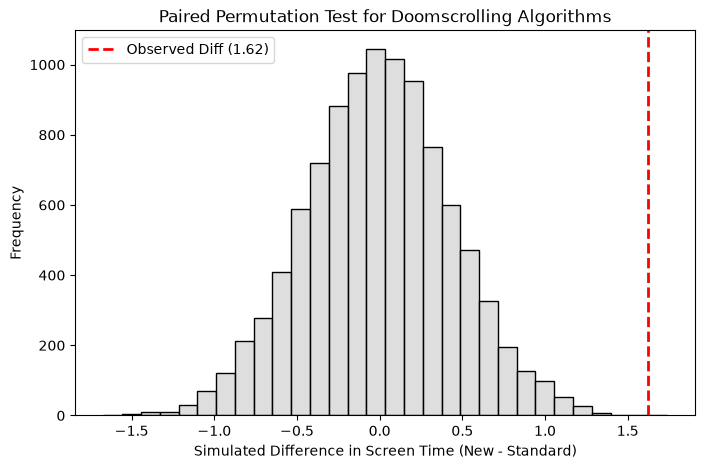

P-value for Paired Permutation Test (Doomscrolling Algorithms): 0.0002


In [9]:
# paired permutation test
def paired_permutation_test(df, col1, col2, n_permutations=10000):
    observed_difference = df[col2] - df[col1]
    observed_stat = observed_difference.mean()
    null_distribution = []
    for _ in range(n_permutations):
        permuted_difference = observed_difference.copy()
        flip = np.random.choice([True, False], size=len(permuted_difference))
        permuted_difference[flip] = -permuted_difference[flip]
        null_distribution.append(permuted_difference.mean())
    null_distribution = np.array(null_distribution)
    p_value = (np.abs(null_distribution) >= np.abs(observed_stat)).mean()
    return observed_stat, p_value, null_distribution

obs_diff, p_value, null_dist = paired_permutation_test(df_doomscrolling, 'standard_time', 'new_time', n_permutations=10000)

plt.figure(figsize=(8, 5))
sns.histplot(null_dist, bins=30, color='lightgray', edgecolor='black')
plt.axvline(obs_diff, color='red', linestyle='dashed', linewidth=2, label=f'Observed Diff ({obs_diff:.2f})')
plt.title('Paired Permutation Test for Doomscrolling Algorithms')
plt.xlabel('Simulated Difference in Screen Time (New - Standard)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

print(f"P-value for Paired Permutation Test (Doomscrolling Algorithms): {p_value:.4f}")

Write a one-paragraph summary of the results for the doomscrolling algorithms. Include the observed difference, the p-value, and a conclusion on whether the new algorithm significantly increases screen time. Be sure to include what the hypothesis test is testing.

The test compares the standard and new algorithms using data from 1000 users. The average screen time with the standard algorithm was 123.79 minutes and the new algorithm had 125.41 minutes, which gives us a difference of 1.62 minutes. Seeing the graph, the observed difference is pretty far from the center of the simulated distribution. The p-value was 0.0002, which is much lower than 0.05. The hypothesis test checks if there is a real difference in average screen time or if it could just happen by chance. If we look at these results, we would see that the new algorithm increases screen time, even though the actual increase is pretty small. 